# 01 · Imágenes Satelitales Sentinel-2 (EuroSAT): Auditoría Radiométrica e Índices Espectrales

Este cuaderno audita las **27.000 escenas oficiales de Sentinel-2 MSI (64×64 píxeles, 10 m/píxel)** distribuidas en 10 clases de uso y cobertura de suelo (*EuroSAT*, Helber et al., 2019), calcula índices espectrales en las bandas visibles ($R, G, B$) y analiza la separabilidad física frente a la rugosidad espacial.

In [1]:
import json
from pathlib import Path
import os
if not Path('reports').is_dir():  # Jupyter abre el cuaderno en notebooks/: se trabaja desde la raíz
    os.chdir('..')
import pandas as pd
from IPython.display import display, Image

auditoria = json.loads(Path('data/cifras_control_eurosat.json').read_text(encoding='utf-8'))
print(json.dumps(auditoria, indent=2, ensure_ascii=False))

{
  "dataset": "EuroSAT RGB (Sentinel-2 MSI, 64x64 px, 10 m/px)",
  "fuente_oficial": "Helber et al. (2019), IEEE JSTARS / HuggingFace timm/eurosat-rgb",
  "licencia": "MIT",
  "total_imagenes_oficial": 27000,
  "conteo_splits_oficial": {
    "train": 16200,
    "val": 5400,
    "test": 5400
  },
  "numero_clases": 10,
  "total_subconjunto_modelado": 27000,
  "n_train": 16200,
  "n_val": 5400,
  "n_test": 5400,
  "pct_velo_atmosferico_global": 30.88,
  "muestra_versionada_png": 50
}


In [2]:
df_27k = pd.read_csv('reports/resumen_clases_27000.csv')
cols = ['clase_id', 'clase', 'nombre_es', 'macro_categoria', 'imagenes_totales', 'exg_medio', 'indice_agua_medio', 'brillo_medio', 'rugosidad_media', 'pct_velo_o_bajo_contraste']
display(df_27k[cols].round(4))

,clase_id,clase,nombre_es,macro_categoria,imagenes_totales,exg_medio,indice_agua_medio,brillo_medio,rugosidad_media,pct_velo_o_bajo_contraste
0,0,AnnualCrop,Cultivo anual,Agrícola,3000,-0.0101,-0.0280,0.4806,0.0144,14.2000
1,1,Forest,Bosque denso,Ecosistema natural,3000,0.0753,0.3198,0.2285,0.0077,98.5000
2,2,HerbaceousVegetation,Vegetación herbácea,Ecosistema natural,3000,-0.0113,0.0474,0.3889,0.0207,17.2000
3,3,Highway,Autopista / vialidad,Infraestructura antrópica,2500,0.0145,0.1083,0.3720,0.0247,5.9200
4,4,Industrial,Zona industrial,Infraestructura antrópica,2500,-0.0173,0.0501,0.4934,0.0522,10.4800
5,5,Pasture,Pastizal ganadero,Agrícola,2000,0.0931,0.2080,0.3183,0.0108,37.4500
6,6,PermanentCrop,Cultivo permanente,Agrícola,2500,-0.0073,-0.0164,0.4612,0.0268,10.8000
7,7,Residential,Zona residencial,Infraestructura antrópica,3000,-0.0148,0.0754,0.4068,0.0436,5.3000
8,8,River,Río / cauce fluvial,Cuerpo de agua,2500,0.0406,0.1947,0.3213,0.0171,4.2400
9,9,SeaLake,Mar / cuerpo lacustre,Cuerpo de agua,3000,0.0264,0.3365,0.2639,0.0032,91.5667


## Mosaico de las 10 clases de cobertura terrestre y espacio espectral (`ExG` vs. Índice de Agua)

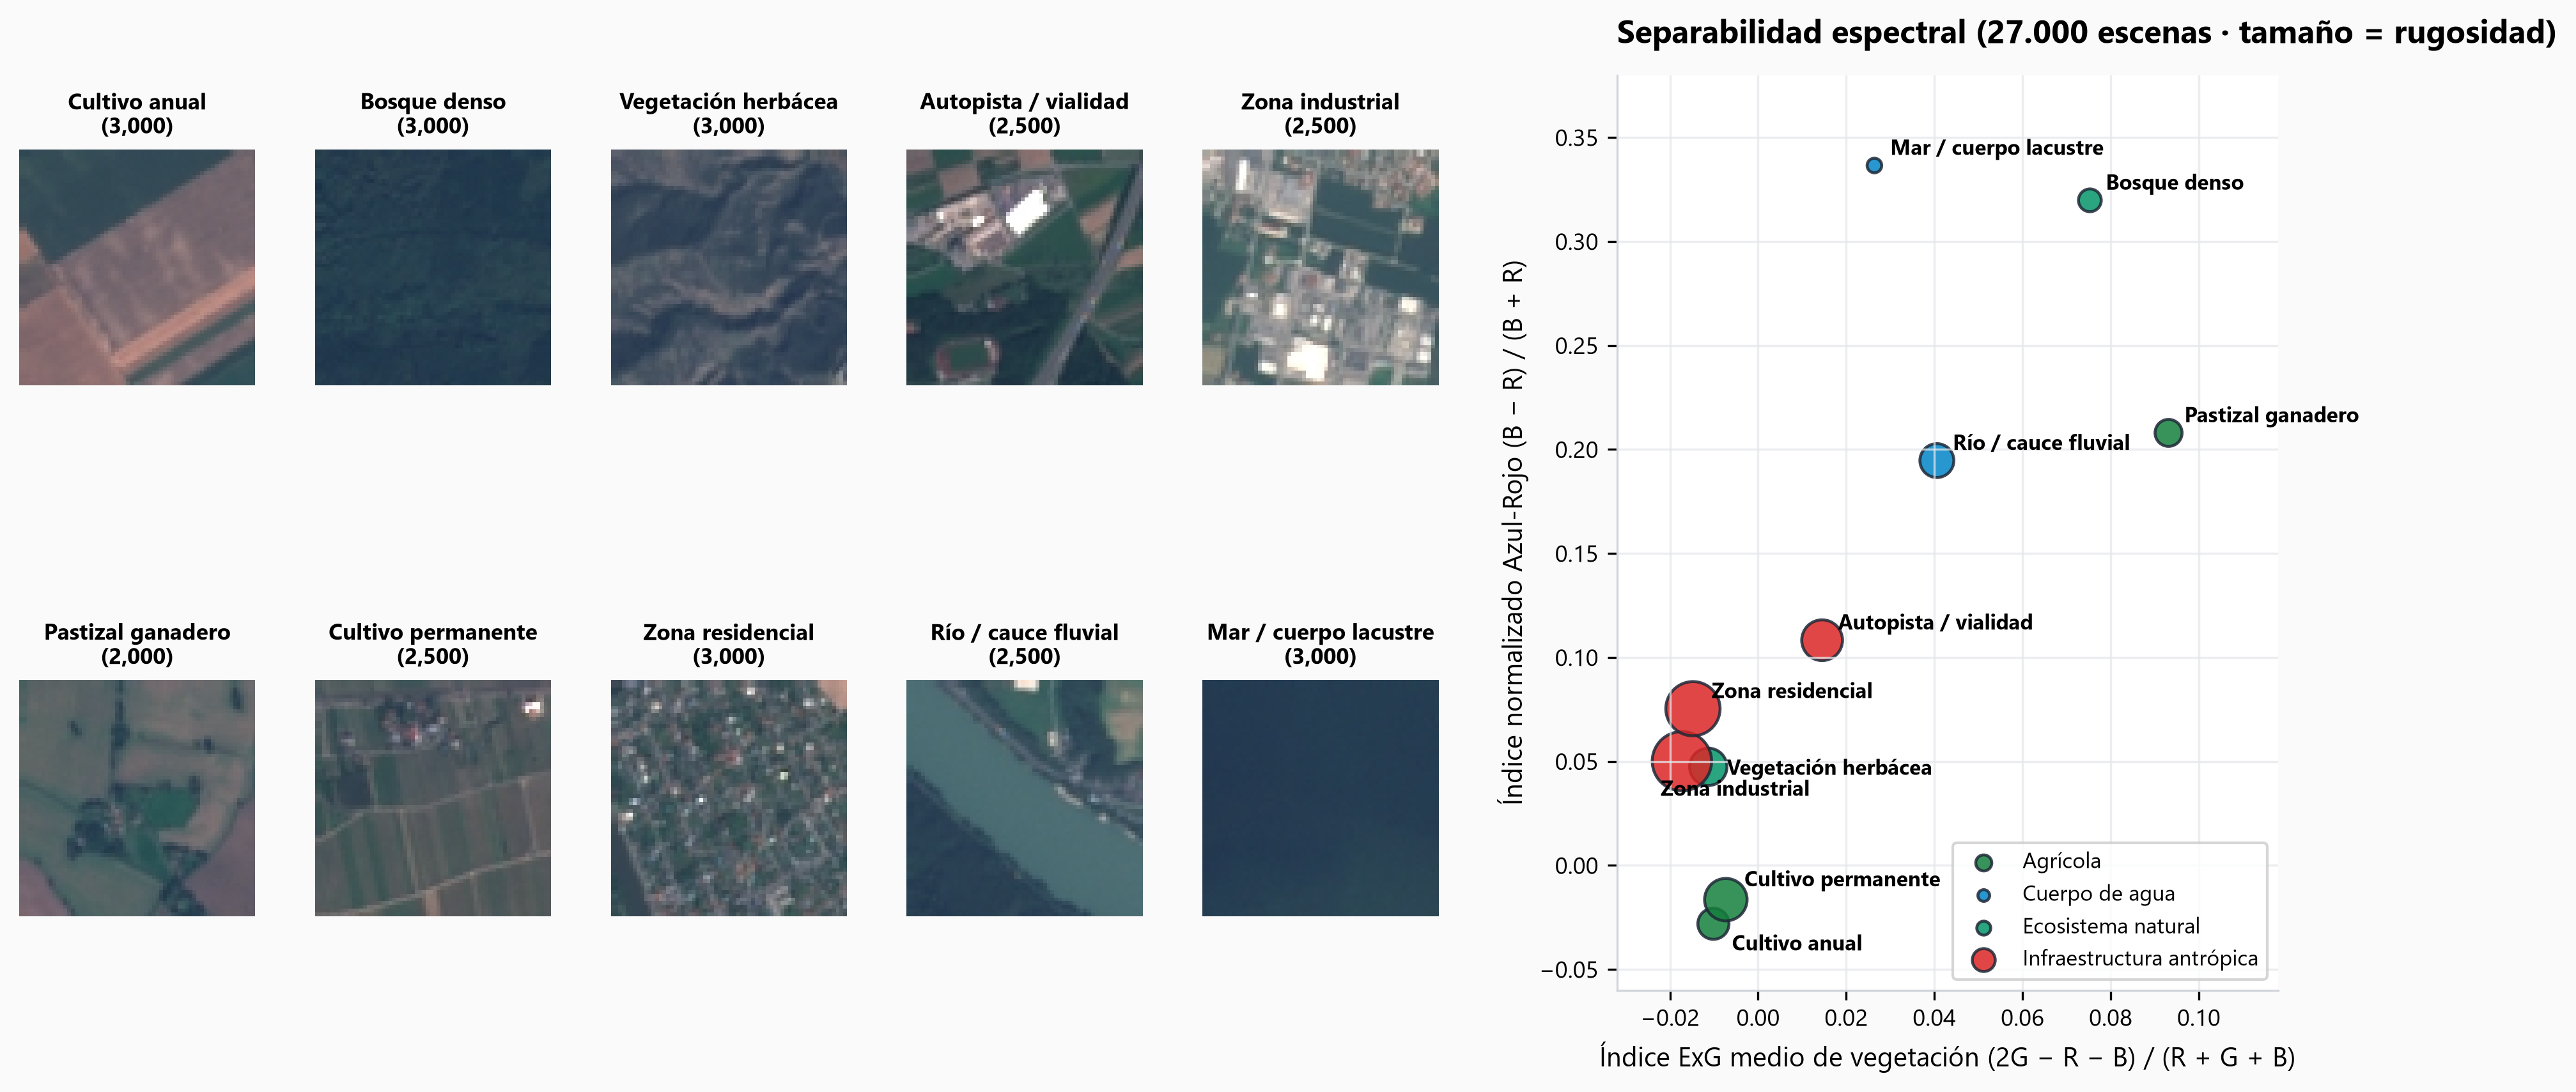

In [3]:
display(Image('reports/figures/01_mosaico_clases_y_espectro_sentinel2.png'))